In [1]:
from fingeo_supplement.utils.finsler_extract import load_finsler_metric
from fingeo_supplement.datasets.process import process_data
from fingeo_supplement.paths import FINGEO_DATA_DIR,FINGEO_OUT_ROOT
import anndata
import pandas as pd
from finsler_embedding.utils import get_grid_pts, get_bounds
import torch
from finsler_embedding import from_points
import numpy as np
import matplotlib.pyplot as plt
from finsler_embedding.experiments.learning import interpolate_V


[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


/home/tblanchard/phd/Finsler-Embedding/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
(FINGEO_DATA_DIR /"central_nervous_system.h5ad").exists()

False

In [3]:
adata = anndata.read_h5ad(FINGEO_DATA_DIR/ "processed/central_nervous_system.h5ad")

emb   = load_finsler_metric(FINGEO_OUT_ROOT/"cns/finsler_metric.pt")
X     = adata.obsm["X_pca"]
ct    = adata.obs["cell_type"].tolist()

# Work on a subsample — the full n_cells x n_cells cost is ~4.3B entries for CNS (see above).
Xi    = X[:5000]
ci    = np.array(ct[:5000])

# M     = emb.directed_cost(Xi)                # (500, 500) asymmetric cost on the subsample
# out   = emb.build_directed_graph(Xi, ci)     # type-level matrix (small: |C| x |C|) is cheap
# F     = emb.finsler_norm(X[:32], (X[1:33] - X[:32]))   # F(x, v) on sample tangent pairs

In [4]:
unique_labels = np.unique(ci)
cmap = plt.colormaps.get_cmap("tab20").resampled(len(unique_labels))

label_to_color = {
    label: cmap(i)
    for i, label in enumerate(unique_labels)
}
point_colors = np.array([label_to_color[label] for label in ci])


In [5]:
directed_distances = emb.directed_cost(Xi)
directed_distances.std()

tensor(0.1134)

In [6]:
from umap import UMAP
def umap_on_points(points, *, n_components, **params):
    coordinates = UMAP(n_components=n_components, **params).fit_transform(
        points.detach().cpu().numpy()
    )
    return torch.as_tensor(
        coordinates, dtype=points.dtype, device=points.device
    )


In [7]:
n_components = 2
results = from_points(
    torch.from_numpy(Xi), # (N, d)
    distances=directed_distances, # (N, N)
    bandwidth=0.25,
    embedding="isomap",
    embedding_input="kernel",
    # embedding=umap_on_points,
    # embedding_input="points",
    embedding_params={"n_neighbors": 10},
    jacobian="local_least_squares",
    jacobian_params={"k": 15},
    n_components=n_components,
)

In [8]:
X_low = results.coordinates
bounds = get_bounds(X_low, margin=0.1)

In [9]:
V = results.drift
V_normed = V / (results.drift_norm_squared.sqrt() + 1e-12).unsqueeze(1)
unit_V = V / (V.norm(dim=1, keepdim=True) + 1e-12)

In [10]:
# Sort by x coords for display
idx = torch.argsort(X_low[:, 0])
X_low_plt = X_low[idx].clone()
V_plt = V[idx].clone()
unit_V_plt = unit_V[idx].clone()
ci_plt = ci[idx]

In [11]:
# Sort by x coords for display
idx = torch.argsort(X_low[:, 0])
X_low_plt = X_low[idx].clone()
V_plt = V[idx].clone()
unit_V_plt = unit_V[idx].clone()
ci_plt = ci[idx]
points_colors_plt = point_colors[idx]


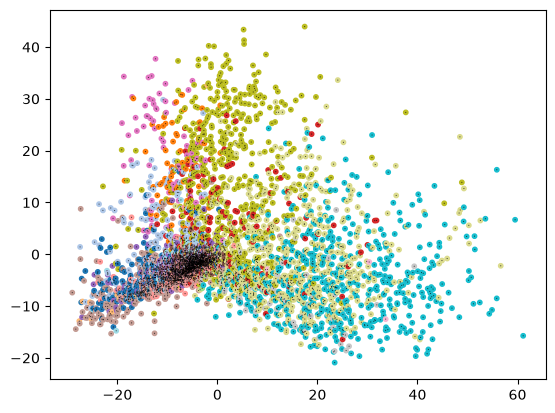

In [12]:
cbar = plt.scatter(
    X_low_plt[:, 0], X_low_plt[:, 1], 
    c=points_colors_plt,s=10
)
skip=1
plt.quiver(
    X_low_plt[::skip, 0],
    X_low_plt[::skip, 1],
    unit_V_plt[::skip, 0],
    unit_V_plt[::skip, 1],
    color="black",
    scale=50,
    angles="xy",
    scale_units="xy",
    alpha = results.admissible[idx][::skip].float().sigmoid()
)

In [13]:
model, loss_list = interpolate_V(X_low, unit_V, dim=n_components)

Interpolating V: 100%|██████████| 500/500 [00:01<00:00, 430.35it/s, loss=0.0987]


/tmp/ipykernel_3048408/2137860415.py:11: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_low[:, 0], X_low[:, 1], c=point_colors, cmap=cmap)


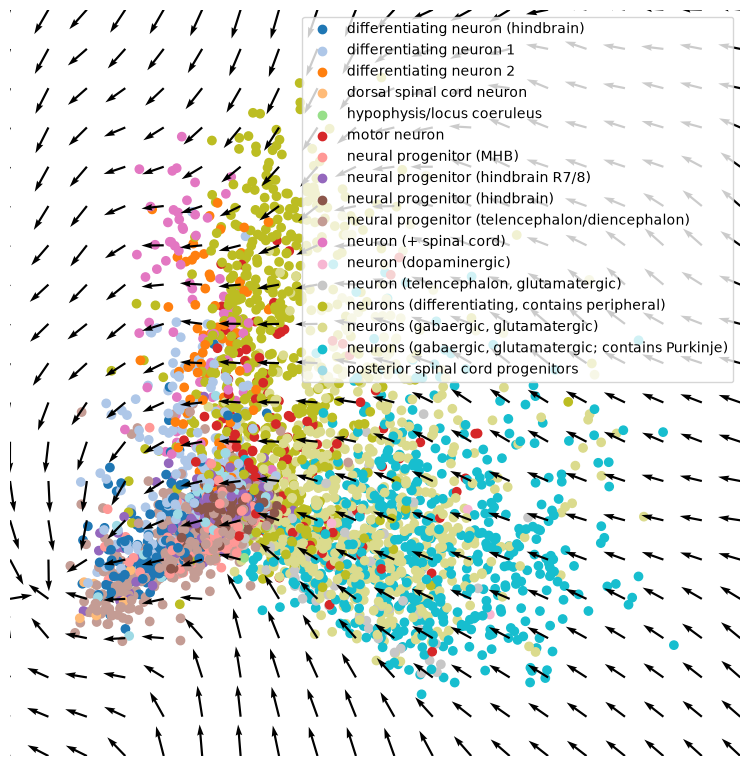

In [14]:
# Grid
x = torch.linspace(bounds[0], bounds[1], 20)
y = torch.linspace(bounds[2], bounds[3], 20)
X, Y = torch.meshgrid(x, y, indexing="ij")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=1)
# grid_points += 1e-1 * torch.randn_like(grid_points)
V_grid = model(grid_points).detach()
V_grid_unit = V_grid / (V_grid.norm(dim=1, keepdim=True) + 1e-12)

plt.figure(figsize=(8, 8))
plt.scatter(X_low[:, 0], X_low[:, 1], c=point_colors, cmap=cmap)
plt.quiver(
    grid_points[:, 0],
    grid_points[:, 1],
    V_grid_unit[:, 0],
    V_grid_unit[:, 1],
    color="black",
    scale=0.3,
    angles="xy",
    scale_units="xy",
)
for label, color in label_to_color.items():
    plt.scatter([], [], color=color, label=str(label))
plt.legend()
plt.xlim(bounds[0], bounds[1])
plt.ylim(bounds[2], bounds[3])
plt.tight_layout()
plt.axis("off")
# plt.savefig("cell_lineage.pdf", dpi=300, bbox_inches="tight")
plt.show()